# Lecture 6: The rest of the world

The sixth model opens the economy. Each good is either exported or imported, the government collects a duty on imports, and the world price of each good responds to how much the country trades. Foreign saving now joins household and public saving in financing investment, and it equals the trade deficit.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium models: relations with the rest of the world](https://www.youtube.com/watch?v=2-I_2LC2s24)
- ✅ Correction: [CGE models: relations with the rest of the world - Correction](https://www.youtube.com/watch?v=_F4qySskb88)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import cge_modeling as cm

## The economy

Production, household income and the government's spending rules are unchanged from the {doc}`fifth notebook <05_investment>`. Trade adds three things.

- Each good has a world price $pe_i$ in foreign currency. With the exchange rate $e$ and an import duty at rate $tm_i$, the domestic consumer price is $P_i = e \cdot pe_i \cdot (1 + tm_i)$.
- Domestic and foreign goods are the same product, and the country either imports or exports each good, never both. The excess demand $ED_i$ is positive for an imported good and negative for an exported one.
- The country is large enough to move world prices. The rest of the world supplies imports or buys exports along a constant-elasticity curve, $ED_i = f_i \cdot pe_i^{\sigma_i}$. For an imported good $\sigma_i > 0$, so buying more raises the world price. For an exported good $\sigma_i < 0$, so selling more lowers it.

The trade balance $tradesold$ is exports minus imports valued at world prices. A deficit is foreign saving, which finances investment alongside household and public saving.

### Variables

Three variables are new: the world price $pe_i$, the excess demand $ED_i$, and the trade balance.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of good <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    pe = cm.Variable("pe", dims="i", description="World price of good <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    savings = cm.Variable("savings", description="Household saving")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government spending")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    INV = cm.Variable("INV", description="Total investment")
    CK = cm.Variable("CK", dims="i", description="Investment demand for good <dim:i>")
    ED = cm.Variable("ED", dims="i", description="Excess demand for good <dim:i>, imports if positive")
    tradesold = cm.Variable("tradesold", description="Trade balance, exports minus imports")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

\(\textbf{Symbol}\),\(\textbf{Description}\)
\(Y_{i}\),\(\text{Output}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{VA}_{i}\),\(\text{Value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{IC}_{i}\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{used}\) \(\text{by}\) \(\text{sector}\) \(\text{i}\)
"\(\mathrm{CIJ}_{i, j}\)",\(\text{Good}\) \(\text{i}\) \(\text{used}\) \(\text{by}\) \(\text{sector}\) \(\text{j}\)
\(\mathrm{KD}_{i}\),\(\text{Capital}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{LD}_{i}\),\(\text{Labor}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(P_{i}\),\(\text{Consumer}\) \(\text{price}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\mathrm{PY}_{i}\),\(\text{Producer}\) \(\text{price}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\mathrm{PVA}_{i}\),\(\text{Price}\) \(\text{of}\) \(\text{value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{PIC}_{i}\),\(\text{Price}\) \(\text{of}\) \(\text{the}\) \(\text{intermediate}\) \(\text{bundle}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)


### Parameters

The new parameters are the import duty rate $tm_i$, the scale $f_i$ and elasticity $\sigma_i$ of the rest of the world's excess supply, and the exchange rate $e$. The course fixes the exchange rate at 1, so it is a parameter here.

In [3]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Household budget share of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    alpha_k = cm.Parameter("alpha_k",
                           dims="i",
                           latex_name=r"\alpha^K",
                           description="Investment budget share of good <dim:i>")
    mps = cm.Parameter("mps", description="Marginal propensity to save")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on good <dim:i>")
    tm = cm.Parameter("tm", dims="i", description="Import duty rate on good <dim:i>")
    f = cm.Parameter("f", dims="i", description="Scale of the rest of the world's excess supply of good <dim:i>")
    sigma = cm.Parameter("sigma", dims="i", description="Price elasticity of excess demand for good <dim:i>")
    e = cm.Parameter("e", description="Exchange rate")
    pubsold = cm.Parameter("pubsold", description="Public balance, revenue minus spending")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    P_Agr = cm.Parameter("P_Agr", latex_name=r"\bar{P}_{Agr}", description="Price of agriculture, the numeraire")

mod.summary("parameters")

\(\textbf{Symbol}\),\(\textbf{Description}\)
\(\alpha_{i}\),\(\text{Capital}\) \(\text{share}\) \(\text{of}\) \(\text{value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(A_{i}\),\(\text{Productivity}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{VA}, i}\)",\(\text{Value}\) \(\text{added}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{output}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{IC}, i}\)",\(\text{Intermediate}\) \(\text{bundle}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{output}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{IJC}, i, j}\)",\(\text{Good}\) \(\text{i}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{the}\) \(\text{intermediate}\) \(\text{bundle}\) \(\text{of}\) \(\text{sector}\) \(\text{j}\)
\(\gamma_{i}\),\(\text{Household}\) \(\text{budget}\) \(\text{share}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\alpha^G_{i}\),\(\text{Government}\) \(\text{budget}\) \(\text{share}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\alpha^K_{i}\),\(\text{Investment}\) \(\text{budget}\) \(\text{share}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\mathrm{mps}\),\(\text{Marginal}\) \(\text{propensity}\) \(\text{to}\) \(\text{save}\)
\(\mathrm{itr}\),\(\text{Income}\) \(\text{tax}\) \(\text{rate}\)


### Equations

Three equations are new. The world price links the consumer price to the world price through the exchange rate and the duty. Excess demand is the rest of the world's constant-elasticity curve. The trade balance values exports minus imports at world prices.

Three equations change. The government budget adds the duty collected on imports, $tm_i \cdot e \cdot pe_i \cdot ED_i$. The course sums this term only over imported goods. Exported goods carry no duty, $tm_i = 0$, so summing over all goods gives the same revenue. Goods market clearing subtracts excess demand: imports add to supply and exports add to demand. The macroeconomic balance subtracts the trade balance, so household saving, public saving and foreign saving together finance investment.

In [4]:
with mod:
    cm.Equation("Tax wedge", PY * (1 + tau), P)
    cm.Equation("World price", P, e * pe * (1 + tm))
    cm.Equation("Excess demand", ED, f * pe**sigma)
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD, alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD, (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))
    cm.Equation("Income", INC, W * LS + R * KS)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC)
    cm.Equation("Saving", savings, mps * DISP_INC)
    cm.Equation("Consumption", P * C, gamma * (1 - mps) * DISP_INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Investment demand", P * CK, alpha_k * INV)
    cm.Equation("Public balance",
                pubsold,
                itr * INC + (tau * PY * Y).sum() + (tm * e * pe * ED).sum() - BUDG_EXP)
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Labor market clearing", LS, LD.sum())
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Goods market clearing", Y, C + CG + CK + CIJ.sum("j") - ED)
    cm.Equation("Trade balance", tradesold, e * (pe * -ED).sum())
    cm.Equation("Macroeconomic balance", savings - INV + pubsold - tradesold, Leon)
    cm.Equation("Numeraire", P.sel(i="Agr"), P_Agr)

mod.equation_table()

,\(\textbf{Name}\),\(\textbf{Equation}\)
\(1\),\(\text{Tax}\) \(\text{wedge}\),\(\mathrm{PY}_{i} \left(1 + \tau_{i}\right) = P_{i}\)
\(2\),\(\text{World}\) \(\text{price}\),\(P_{i} = e \cdot \mathrm{pe}_{i} \left(1 + \mathrm{tm}_{i}\right)\)
\(3\),\(\text{Excess}\) \(\text{demand}\),\(\mathrm{ED}_{i} = f_{i} \cdot \mathrm{pe}_{i}^{\sigma_{i}}\)
\(4\),\(\text{Value}\) \(\text{added}\) \(\text{demand}\),"\(\mathrm{VA}_{i} = \psi_{\mathrm{VA}, i} \cdot Y_{i}\)"
\(5\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{demand}\),"\(\mathrm{IC}_{i} = \psi_{\mathrm{IC}, i} \cdot Y_{i}\)"
\(6\),\(\text{Zero}\) \(\text{profit}\),\(\mathrm{PY}_{i} \cdot Y_{i} = \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i} + \mathrm{PIC}_{i} \cdot \mathrm{IC}_{i}\)
\(7\),\(\text{Value}\) \(\text{added}\) \(\text{production}\),\(\mathrm{VA}_{i} = A_{i} \cdot \mathrm{KD}_{i}^{\alpha_{i}} \cdot \mathrm{LD}_{i}^{1 - \alpha_{i}}\)
\(8\),\(\text{Capital}\) \(\text{demand}\),\(R \cdot \mathrm{KD}_{i} = \alpha_{i} \cdot \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i}\)
\(9\),\(\text{Labor}\) \(\text{demand}\),\(W \cdot \mathrm{LD}_{i} = \left(1 - \alpha_{i}\right) \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i}\)
\(10\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{price}\),"\(\mathrm{PIC}_{j} \cdot \mathrm{IC}_{j} = \sum_{i} P_{i} \cdot \mathrm{CIJ}_{i, j}\)"


In [5]:
mod.compile();

Compiling a model with 61 equations, 61 variables, 49 parameters


The model has 61 equations in 61 variables. The correction fixes $P_{Agr}$ directly and reports 60, the same system.

## Data

The correction's SAM adds a rest-of-the-world account, `RoW`. Its row records each good's trade at world prices, with exports negative: the country exports 250 of agriculture and 30 of services and imports 430 of industry. The `RoW` column pays 150 into the saving account `Inv`, which is the trade deficit, financed by foreign saving. The public sector runs a deficit of 900, and households save 1850.

The government's 1320 from industry includes 300 of import duty on top of the indirect tax. The SAM does not separate the two, so the duties enter as data of their own. The elasticities $\sigma_i$ come from the correction program: -3 for the two exported goods and 3 for imported industry.

In [6]:
accounts = ["LD", "KD", "Hld", "Gvt", *sectors, "Inv", "RoW"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1100.0, 1700.0, 4150.0]
sam.loc["KD", sectors] = [250.0, 1800.0, 550.0]
sam.loc["Hld", ["LD", "KD"]] = [6950.0, 2600.0]
sam.loc["Gvt", ["Hld", *sectors]] = [1400.0, 150.0, 1320.0, 280.0]
sam.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [400.0, 900.0, 2750.0]
sam.loc[sectors, "Inv"] = [200.0, 800.0, 100.0]
sam.loc[sectors, sectors] = [[1100.0, 900.0, 1100.0],
                             [2200.0, 3150.0, 3300.0],
                             [850.0, 2250.0, 1100.0]]
sam.loc["Inv", ["Hld", "Gvt", "RoW"]] = [1850.0, -900.0, 150.0]
sam.loc["RoW", sectors] = [-250.0, 430.0, -30.0]

import_duties = pd.Series([0.0, 300.0, 0.0], index=sectors)
trade_elasticities = pd.Series([-3.0, 3.0, -3.0], index=sectors)

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,Hld,Gvt,Agr,Ind,Serv,Inv,RoW
LD,0.0,0.0,0.0,0.0,1100.0,1700.0,4150.0,0.0,0.0
KD,0.0,0.0,0.0,0.0,250.0,1800.0,550.0,0.0,0.0
Hld,6950.0,2600.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Gvt,0.0,0.0,1400.0,0.0,150.0,1320.0,280.0,0.0,0.0
Agr,0.0,0.0,1700.0,400.0,1100.0,900.0,1100.0,200.0,0.0
Ind,0.0,0.0,1200.0,900.0,2200.0,3150.0,3300.0,800.0,0.0
Serv,0.0,0.0,3400.0,2750.0,850.0,2250.0,1100.0,100.0,0.0
Inv,0.0,0.0,1850.0,-900.0,0.0,0.0,0.0,0.0,150.0
RoW,0.0,0.0,0.0,0.0,-250.0,430.0,-30.0,0.0,0.0


## Calibration

The normalization changes from the {ref}`third <examples/building_a_cge/03_public_administration:Calibration>`, fourth and fifth notebooks. There the producer prices were 1 and the consumer prices $1 + \tau_i$. The course now sets the consumer prices to 1, $P_{0,i} = 1$, and derives the producer prices $PY_{0,i} = \frac{1}{1 + \tau_i}$.

Trade needs three steps. Domestic output is a goods column's total less its `RoW` entry and its import duty. Excess demand at domestic prices is the `RoW` entry plus the duty, so industry's imports of 430 at world prices are worth 730 at home. The duty rate follows from the duty collected, $importcoll_i = tm_i \cdot pe_{0,i} \cdot ED_{0,i}$ with $pe_{0,i} = \frac{1}{1 + tm_i}$:

$$tm_i = \frac{importcoll_i}{P_{0,i} \cdot ED_{0,i} - importcoll_i}.$$

The scale of each excess supply curve is then $f_i = \frac{ED_{0,i}}{pe_{0,i}^{\sigma_i}}$. The exchange rate is normalized to 1.

In [7]:
def calibrate_model(mod, sam, import_duties, trade_elasticities):
    LD = sam.loc["LD", sectors].values
    KD = sam.loc["KD", sectors].values
    CIJ = sam.loc[sectors, sectors].values
    C = sam.loc[sectors, "Hld"].values
    CG = sam.loc[sectors, "Gvt"].values
    CK = sam.loc[sectors, "Inv"].values
    TRADE = sam.loc["RoW", sectors].values
    IMPDUTY = import_duties.values
    INDTAX = sam.loc["Gvt", sectors].values - IMPDUTY
    DIRTAX = sam.loc["Gvt", "Hld"]
    savings = sam.loc["Inv", "Hld"]
    sigma = trade_elasticities.values

    P = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0
    e = 1.0

    Y = (sam[sectors].sum(axis=0).values - TRADE - IMPDUTY) / P
    tau = INDTAX / (P * Y - INDTAX)
    PY = P / (1 + tau)

    CIJ = CIJ / P[:, None]
    C = C / P
    CG = CG / P
    CK = CK / P

    LS = LD.sum()
    KS = KD.sum()
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC
    VA = (PY * Y - PIC * IC) / PVA
    alpha = R * KD / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))

    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    ED = (TRADE + IMPDUTY) / P
    tm = np.where(ED > 0, IMPDUTY / (P * ED - IMPDUTY), 0.0)
    pe = P / (e * (1 + tm))
    f = ED / pe**sigma
    tradesold = e * (pe * -ED).sum()

    INC = W * LS + R * KS
    itr = DIRTAX / INC
    DISP_INC = (1 - itr) * INC
    mps = savings / DISP_INC
    gamma = P * C / ((1 - mps) * DISP_INC)
    U = np.prod(C**gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP
    INV = (P * CK).sum()
    alpha_k = P * CK / INV

    pubsold = itr * INC + (tau * PY * Y).sum() + (tm * e * pe * ED).sum() - BUDG_EXP
    Leon = savings - INV + pubsold - tradesold
    P_Agr = P[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    sam=sam,
                                    import_duties=import_duties,
                                    trade_elasticities=trade_elasticities)

In [8]:
pd.DataFrame({name: calibrated_values[name] for name in ["Y", "ED", "tau", "tm", "pe", "sigma"]},
             index=sectors).round(4)

,Y,ED,tau,tm,pe,sigma
Agr,5650.0,-250.0,0.0273,0.0000,1.000,-3.0
Ind,10820.0,730.0,0.1041,0.6977,0.589,3.0
Serv,10480.0,-30.0,0.0275,0.0000,1.000,-3.0


In [9]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Cutting the indirect tax rates

The correction cuts all three indirect tax rates by 10%, the same experiment as in the {ref}`fifth notebook <examples/building_a_cge/05_investment:Cutting the indirect tax rates>`.

In [10]:
tax_cut = mod.simulate(initial_state=calibrated_values,
                       final_delta_pct={"tau": 0.9})
assert tax_cut["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||      Step     
 ──────────────────────────────────────────────────────────────────────────────────── 
  Path (rk4)      ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000014   100/100  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000004     3/  3

The correction reports:

| | Agr | Ind | Serv |
|---|---|---|---|
| $Y$ growth (%) | 0.399 | 0.344 | -0.371 |
| $C$ growth (%) | 1.574 | 1.995 | 1.235 |
| $P$ growth (%) | 0 | -0.412 | 0.335 |
| Trade growth (%) | 0 | -1.231 | -1.000 |

with trade measured as agricultural and service exports and industrial imports, and growth of 1.483% in the wage, 1.818% in the return to capital and 1.574% in income, with a Fisher consumer price index of 1.001. Growth in excess demand $ED_i$ is growth in exports for an exported good, because both values are negative.

In [11]:
def growth(result, name):
    variables = result["optimizer"]["variables"]
    initial = variables[name].isel(step=0).values
    final = variables[name].isel(step=-1).values
    return 100 * (final / initial - 1)


def sector_growth(result, names):
    return pd.DataFrame({f"{name} growth (%)": growth(result, name) for name in names},
                        index=sectors).T


def aggregate_growth(result):
    variables = result["optimizer"]["variables"]
    benchmark_prices = variables["P"].isel(step=0).values
    benchmark_consumption = variables["C"].isel(step=0).values
    prices = variables["P"].isel(step=-1).values
    consumption = variables["C"].isel(step=-1).values

    laspeyres = (prices * benchmark_consumption).sum() / (benchmark_prices * benchmark_consumption).sum()
    paasche = (prices * consumption).sum() / (benchmark_prices * consumption).sum()

    return pd.Series({"W growth (%)": growth(result, "W"),
                      "R growth (%)": growth(result, "R"),
                      "INC growth (%)": growth(result, "INC"),
                      "PIndC": 100 * np.sqrt(laspeyres * paasche)})


sector_growth(tax_cut, names=["Y", "C", "P", "ED"]).round(3)

,Agr,Ind,Serv
Y growth (%),0.399,0.344,-0.371
C growth (%),1.574,1.995,1.235
P growth (%),0.000,-0.412,0.335
ED growth (%),0.000,-1.231,-1.000


In [12]:
aggregate_growth(tax_cut).round(3)

W growth (%)        1.483
R growth (%)        1.818
INC growth (%)      1.574
PIndC             100.102
dtype: float64

In [13]:
float(tax_cut["optimizer"]["variables"]["Leon"].isel(step=-1))

-2.2990813146568574e-13

Every number matches the correction, and $Leon$ is zero up to floating-point error.

The table below follows the flows the correction's listing leaves out, valued in units of the numeraire.

In [14]:
def model_state(result, step):
    node = result["optimizer"].isel(step=step)
    return {**node["variables"].data_vars, **node["parameters"].data_vars}


def flows(state):
    duty = state["tm"] * state["e"] * state["pe"] * state["ED"]
    return pd.Series({"household saving": float(state["savings"]),
                      "government spending": float(state["BUDG_EXP"]),
                      "import duty revenue": float(duty.sum()),
                      "trade balance": float(state["tradesold"]),
                      "investment": float(state["INV"])})


tax_cut_flows = pd.DataFrame({"benchmark": flows(model_state(tax_cut, step=0)),
                              "tau x 0.9": flows(model_state(tax_cut, step=-1))})
tax_cut_flows["change"] = tax_cut_flows["tau x 0.9"] - tax_cut_flows["benchmark"]
tax_cut_flows.round(1)

,benchmark,tau x 0.9,change
household saving,1850.0,1879.1,29.1
government spending,4050.0,3931.7,-118.3
import duty revenue,300.0,295.1,-4.9
trade balance,-150.0,-143.2,6.8
investment,1100.0,1122.3,22.3


Industry carries the highest indirect tax, so its consumer price falls the most. The exchange rate and the duty are fixed, so industry's world price falls in proportion, and the rest of the world supplies 1.2% fewer imports. Services get more expensive, their world price rises, and foreign buyers take 1% fewer of them. Agriculture's consumer price is the numeraire and carries no duty, so its world price and its exports do not move.

Lower tax revenue cuts government spending by 118, because the public balance is fixed. Households save 29 more out of their higher income, and the trade deficit narrows by 7. Investment rises by the difference, 22.

## Who absorbs a tariff change

The trade balance is a new term in the macroeconomic balance, so the closure has to decide which quantity adjusts. The course fixes the exchange rate and the public balance. Foreign saving, the trade deficit, is then free, and whatever the rest of the world lends goes into investment.

The other common closure fixes foreign saving instead and lets the exchange rate float. The trade balance then cannot move, and the exchange rate adjusts until exports pay for imports. As in the {ref}`fourth notebook <examples/building_a_cge/04_household_savings:Choosing the closure>`, {meth}`~cge_modeling.base.cge.CGEModel.reassign_roles` builds this closure from a copy of the model.

In [15]:
floating_rate = mod.copy().reassign_roles(to_parameters="tradesold", to_variables="e").compile()

Compiling a model with 61 equations, 61 variables, 49 parameters


The two closures share the benchmark, so they can be compared on the same experiment. The experiment is the country's own tariff on industrial imports, from free trade to a duty of 150%. For each closure, the first simulation removes the duty and solves the model exactly. The second starts from that solution and raises the duty along one solution path of 200 steps.

In [16]:
def tariff_sweep(model, highest_duty=1.5):
    """Return trade, investment and the exchange rate as the duty on industrial imports rises from 0."""
    free_trade = model.simulate(initial_state=calibrated_values,
                                final_values={"tm": np.zeros(len(sectors))},
                                progressbar=False)
    path = model.simulate(initial_state=free_trade,
                           final_values={"tm": np.where(np.array(sectors) == "Ind", highest_duty, 0.0)},
                           n_path_steps=200,
                           use_optimizer=False,
                           progressbar=True)["path"]
    path = xr.merge([path["variables"].to_dataset(inherit=False),
                     path["parameters"].to_dataset(inherit=False)])
    return pd.DataFrame({"duty": path["tm"].sel(i="Ind").values,
                         "imports": path["ED"].sel(i="Ind").values,
                         "exports": -path["ED"].sel(i=["Agr", "Serv"]).sum("i").values,
                         "investment": path["INV"].values,
                         "exchange rate": path["e"].values})

In [17]:
closures = {"fixed exchange rate": mod, "fixed trade balance": floating_rate}
sweeps = {label: tariff_sweep(model) for label, model in closures.items()}

Progress               Elapsed   Residual     ||Jᵀf||      Step     
 ───────────────────────────────────────────────────────────────────────────────── 
  Path (rk4)   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000268   0.00295150   200/200

Progress               Elapsed   Residual     ||Jᵀf||      Step     
 ───────────────────────────────────────────────────────────────────────────────── 
  Path (rk4)   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000020   0.00011846   200/200

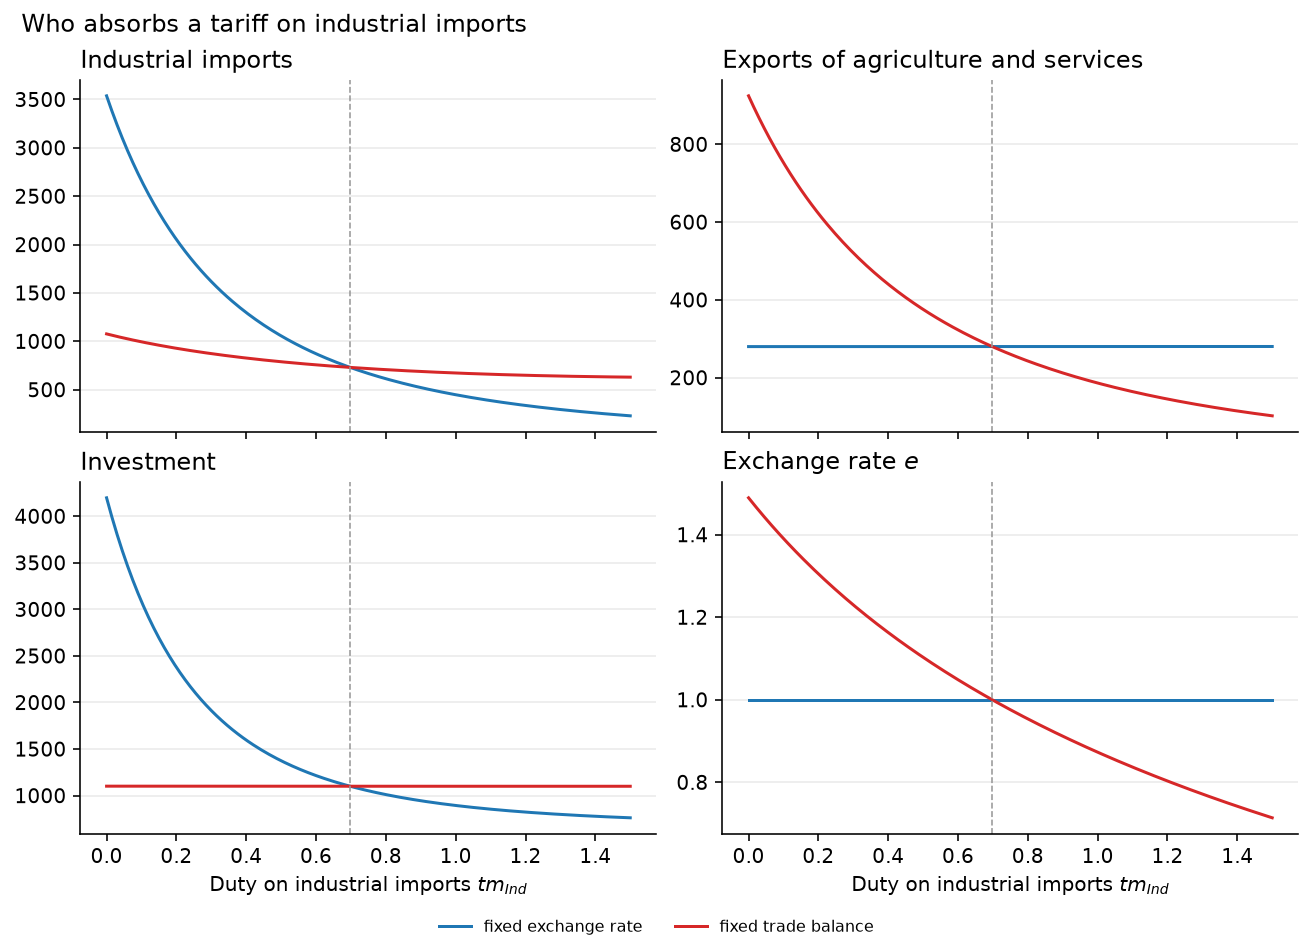

In [18]:
benchmark_duty = float(calibrated_values["tm"][sectors.index("Ind")])
closure_colors = {"fixed exchange rate": "C0", "fixed trade balance": "C3"}
panel_titles = {"imports": "Industrial imports",
                "exports": "Exports of agriculture and services",
                "investment": "Investment",
                "exchange rate": "Exchange rate $e$"}

fig, axes = plt.subplots(nrows=2,
                         ncols=2,
                         figsize=(9, 6.5),
                         dpi=144,
                         sharex=True,
                         layout="constrained")
for ax, (column, title) in zip(axes.flat, panel_titles.items()):
    for label, sweep in sweeps.items():
        ax.plot(sweep["duty"],
                sweep[column],
                color=closure_colors[label],
                label=label)
    ax.axvline(benchmark_duty,
               color="0.6",
               linewidth=0.8,
               linestyle="--")
    ax.set_title(title,
                 loc="left")
    ax.grid(axis="y",
            color="0.92")
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[1]:
    ax.set_xlabel("Duty on industrial imports $tm_{Ind}$")
fig.suptitle("Who absorbs a tariff on industrial imports",
             x=0.01,
             ha="left")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

Imports and exports are volumes at benchmark domestic prices, and investment is in units of the numeraire. The table gives the two ends of each sweep.

In [19]:
pd.concat({label: sweep.iloc[[0, -1]].set_index("duty") for label, sweep in sweeps.items()}).round(3)

imports  exports  investment  exchange rate
                    duty                                              
fixed exchange rate 0.0   3536.741  279.809    4197.195          1.000
                    1.5    229.643  280.089     761.173          1.000
fixed trade balance 0.0   1076.284  924.462    1100.892          1.489
                    1.5    629.340  101.858    1099.755          0.714

With a fixed exchange rate, no price adjusts to hold imports back. Removing the duty raises industrial imports from 730 to about 3540, and the trade deficit widens to match. Foreign lending finances the deficit, so investment rises to about 4200. Exports hardly move, because the numeraire and the fixed exchange rate pin the world prices of agriculture and services.

With a fixed trade balance, the exchange rate adjusts instead. Removing the duty depreciates the currency by 49%, which makes the country's exports cheaper abroad. Exports more than triple, to about 920, and pay for the extra imports, which rise only to about 1080. A higher duty works the other way: the currency appreciates, and at a duty of 150% exports fall to about 100. Investment stays at 1100, because foreign saving is fixed and household and public saving barely change. In this closure a duty on imports acts as a tax on exports, the symmetry between import and export taxes that Lerner (1936) showed.

The economy here trades each good in one direction only, because domestic and foreign goods are the same product. The {doc}`next lecture <07_armington>` treats them as imperfect substitutes, so a country can import and export the same good.

## Authors

- Created by Jesse Grabowski, November 26, 2026

## Watermark

In [20]:
%load_ext watermark
%watermark -n -u -v -iv -m -w -p pytensor

Last updated: Fri, 27 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

pytensor: 3.3.8

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1
xarray      : 2026.9.0

Watermark: 2.6.0

